# 🔥 AI for IoT – Practical 1: Fire Alarm Detection

## 1. Objective
Build a **binary classification model** that predicts the state of an IoT-connected smoke detector from its environmental sensor readings.

- **Core task:** Logistic Regression
- **Bonus:** XGBoost, and a comparison of the two models

## 2. Dataset
[Kaggle – Smoke Detection Dataset](https://www.kaggle.com/datasets/deepcontractor/smoke-detection-dataset) (`smoke_detection_iot.csv`)

- **Inputs (X):** sensor readings: temperature, humidity, gases (TVOC, eCO2, raw H2, raw ethanol), pressure, particulate matter (PM, NC)
- **Target (y):** `Fire Alarm` → `1` = alarm ON (fire/smoke), `0` = normal conditions

> **On Kaggle:** *Add Input → Datasets →* search "smoke detection dataset" (deepcontractor). The loader below finds the CSV in `/kaggle/input`, or next to the notebook when it runs locally.

---
# 3. Core Task: Logistic Regression Classifier

## A. Setup and Preprocessing

### A.1 Import libraries

In [1]:
import os

# Data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning (scikit-learn)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # fixed seed so that the split and the results can be reproduced

### A.2 Load and inspect the data

In [2]:
# Look for the CSV in the Kaggle inputs first, then next to this notebook
csv_path = None
for root in ["/kaggle/input", "."]:
    for dirpath, _, files in os.walk(root):
        if "smoke_detection_iot.csv" in files:
            csv_path = os.path.join(dirpath, "smoke_detection_iot.csv")
            break
    if csv_path:
        break

assert csv_path is not None, "smoke_detection_iot.csv not found - attach the dataset to the notebook."
print("Loading:", csv_path)

df = pd.read_csv(csv_path)
print("Shape:", df.shape)
df.head()

Loading: .\smoke_detection_iot.csv
Shape: (62630, 16)


,Unnamed: 0,UTC,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,CNT,Fire Alarm
0,0,1654733331,20.000,57.36,0,400,12306,18520,939.735,0.0,0.0,0.0,0.0,0.0,0,0
1,1,1654733332,20.015,56.67,0,400,12345,18651,939.744,0.0,0.0,0.0,0.0,0.0,1,0
2,2,1654733333,20.029,55.96,0,400,12374,18764,939.738,0.0,0.0,0.0,0.0,0.0,2,0
3,3,1654733334,20.044,55.28,0,400,12390,18849,939.736,0.0,0.0,0.0,0.0,0.0,3,0
4,4,1654733335,20.059,54.69,0,400,12403,18921,939.744,0.0,0.0,0.0,0.0,0.0,4,0


In [3]:
# Column names, data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 62630 entries, 0 to 62629
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      62630 non-null  int64  
 1   UTC             62630 non-null  int64  
 2   Temperature[C]  62630 non-null  float64
 3   Humidity[%]     62630 non-null  float64
 4   TVOC[ppb]       62630 non-null  int64  
 5   eCO2[ppm]       62630 non-null  int64  
 6   Raw H2          62630 non-null  int64  
 7   Raw Ethanol     62630 non-null  int64  
 8   Pressure[hPa]   62630 non-null  float64
 9   PM1.0           62630 non-null  float64
 10  PM2.5           62630 non-null  float64
 11  NC0.5           62630 non-null  float64
 12  NC1.0           62630 non-null  float64
 13  NC2.5           62630 non-null  float64
 14  CNT             62630 non-null  int64  
 15  Fire Alarm      62630 non-null  int64  
dtypes: float64(8), int64(8)
memory usage: 7.6 MB


In [4]:
# Number of missing values in each column
df.isnull().sum()

Unnamed: 0        0
UTC               0
Temperature[C]    0
Humidity[%]       0
TVOC[ppb]         0
eCO2[ppm]         0
Raw H2            0
Raw Ethanol       0
Pressure[hPa]     0
PM1.0             0
PM2.5             0
NC0.5             0
NC1.0             0
NC2.5             0
CNT               0
Fire Alarm        0
dtype: int64

#### Handling missing data
`.isnull().sum()` shows the number of missing values per column. The cell below handles them so that the notebook also works on a copy of the data that has gaps:
- a missing **numeric** sensor value is replaced by the **median** of its column (imputation). The median is less affected than the mean by the large sensor spikes recorded during fires;
- any row that is still incomplete is removed.

In [5]:
missing_before = df.isnull().sum().sum()

num_cols = df.select_dtypes(include=np.number).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())   # imputation with the median
df = df.dropna()                                            # removal of anything still missing

print(f"Missing values before: {missing_before} | after: {df.isnull().sum().sum()} | rows kept: {len(df)}")

Missing values before: 0 | after: 0 | rows kept: 62630


#### Class balance of the target

            samples  proportion
Fire Alarm                     
0             17873       0.285
1             44757       0.715


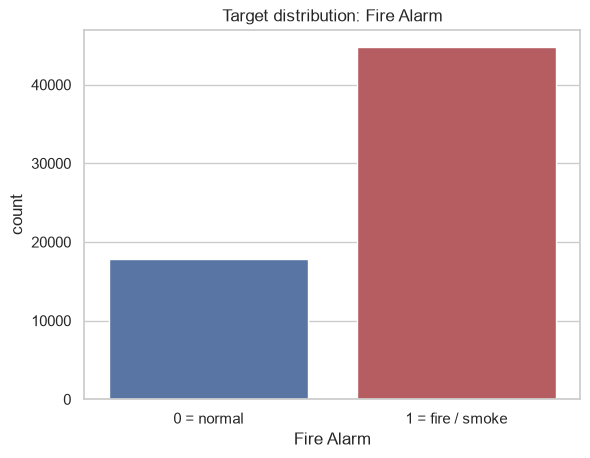

In [6]:
counts = df["Fire Alarm"].value_counts().sort_index()
print(pd.DataFrame({"samples": counts, "proportion": (counts / len(df)).round(3)}))

ax = sns.countplot(x="Fire Alarm", hue="Fire Alarm", data=df, palette=["#4C72B0", "#C44E52"], legend=False)
ax.set_xticks([0, 1], ["0 = normal", "1 = fire / smoke"])
ax.set_title("Target distribution: Fire Alarm")
plt.show()

The two classes are **not balanced**: most samples have the alarm ON. For this reason:
- the train/test split is **stratified**, so the test set keeps the same class proportions;
- the model is judged with **Precision, Recall and F1-Score**, not only Accuracy.

### A.3 Define features (X) and target (y)

`Fire Alarm` is the target `y`. The features `X` are the **12 sensor readings**. Three columns are not sensor measurements and are removed:
- `Unnamed: 0`: the row number of the CSV file;
- `UTC`: the timestamp of the reading;
- `CNT`: a sample counter that restarts at 0 at the start of each recording.

A real detector must decide from what its sensors measure, not from the time or the position of a sample in a file.

In [7]:
TARGET = "Fire Alarm"
DROP_COLS = ["Unnamed: 0", "UTC", "CNT"]   # not sensor measurements

X = df.drop(columns=[TARGET] + DROP_COLS)
y = df[TARGET]

# XGBoost (bonus) does not accept '[', ']' or '<' in feature names: "Temperature[C]" -> "Temperature_C"
X.columns = X.columns.str.replace("[", "_", regex=False).str.replace("]", "", regex=False)

print("Features:", list(X.columns))
print("X shape:", X.shape, "| y shape:", y.shape)

Features: ['Temperature_C', 'Humidity_%', 'TVOC_ppb', 'eCO2_ppm', 'Raw H2', 'Raw Ethanol', 'Pressure_hPa', 'PM1.0', 'PM2.5', 'NC0.5', 'NC1.0', 'NC2.5']
X shape: (62630, 12) | y shape: (62630,)


### A.4 Split the data (80% training / 20% testing)

The split is done **before** the scaling of A.5. The scaler then computes its mean and standard deviation on the training set only, so nothing from the test set is used during training (no *data leakage*).

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,            # 20% for testing, 80% for training
    stratify=y,                # same class proportions in both sets
    random_state=RANDOM_STATE,
)

print("Training set:", X_train.shape, "| Test set:", X_test.shape)
print("Fire ratio  -> train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Training set: (50104, 12) | Test set: (12526, 12)
Fire ratio  -> train: 0.715 | test: 0.715


### A.5 Feature scaling with `StandardScaler` (mandatory)

The sensors have very different units and ranges (see the table below). Logistic Regression is trained by an optimisation algorithm and applies the same regularisation to every weight, so features with large values would dominate the others.
`StandardScaler` transforms each feature to **mean 0 and standard deviation 1**: $z = (x - \mu) / \sigma$.

In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn mu and sigma on the training set only
X_test_scaled  = scaler.transform(X_test)        # apply the same mu and sigma to the test set

# Ranges before and after scaling (training set)
pd.DataFrame({
    "mean before": X_train.mean(),
    "std before":  X_train.std(),
    "max before":  X_train.max(),
    "mean after":  X_train_scaled.mean(axis=0),
    "std after":   X_train_scaled.std(axis=0),
}).round(2)

,mean before,std before,max before,mean after,std after
Temperature_C,15.95,14.36,59.93,-0.0,1.0
Humidity_%,48.57,8.82,75.20,-0.0,1.0
TVOC_ppb,1922.88,7755.97,60000.00,-0.0,1.0
eCO2_ppm,667.74,1903.80,60000.00,-0.0,1.0
Raw H2,12942.30,271.17,13803.00,0.0,1.0
Raw Ethanol,19754.25,606.98,21410.00,-0.0,1.0
Pressure_hPa,938.63,1.32,939.86,0.0,1.0
PM1.0,100.89,925.31,14318.17,0.0,1.0
PM2.5,186.07,1991.55,45432.26,-0.0,1.0
NC0.5,490.21,4259.46,61482.03,0.0,1.0


## B. Training and Evaluation

### B.1 Train the Logistic Regression model

In [10]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)   # trained on the scaled features

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

### B.2 Make predictions on the test set

In [11]:
y_pred_lr = log_reg.predict(X_test_scaled)

# First 10 test samples: true label vs predicted label
pd.DataFrame({"true": y_test.values[:10], "predicted": y_pred_lr[:10]}).T

,0,1,2,3,4,5,6,7,8,9
true,1,1,0,0,1,1,0,1,0,1
predicted,1,1,0,1,1,1,0,1,0,1


### B.3 Evaluate performance

- **Accuracy** = (TP + TN) / total: share of correct predictions
- **Precision** = TP / (TP + FP): when the model says *fire*, how often it is right
- **Recall** = TP / (TP + FN): share of the real fires that the model detects
- **F1-Score** = harmonic mean of Precision and Recall

(TP: fire detected · TN: normal recognised · FP: false alarm · FN: missed fire)

In [12]:
def evaluate(name, y_true, y_pred):
    # Compute the four required metrics, print them and return them as a dict
    res = {
        "Model":     name,
        "Accuracy":  metrics.accuracy_score(y_true, y_pred),
        "Precision": metrics.precision_score(y_true, y_pred),
        "Recall":    metrics.recall_score(y_true, y_pred),
        "F1-Score":  metrics.f1_score(y_true, y_pred),
    }
    for k, v in res.items():
        if k != "Model":
            print(f"{k:<10}: {v:.4f}")
    return res


print("=== Logistic Regression ===")
res_lr = evaluate("Logistic Regression", y_test, y_pred_lr)
print("\nDetailed report per class:\n")
print(metrics.classification_report(y_test, y_pred_lr, target_names=["0 = normal", "1 = fire"], digits=4))

=== Logistic Regression ===
Accuracy  : 0.8951
Precision : 0.9090
Recall    : 0.9482
F1-Score  : 0.9281

Detailed report per class:

              precision    recall  f1-score   support

  0 = normal     0.8545    0.7622    0.8057      3575
    1 = fire     0.9090    0.9482    0.9281      8951

    accuracy                         0.8951     12526
   macro avg     0.8817    0.8552    0.8669     12526
weighted avg     0.8934    0.8951    0.8932     12526



### B.4 Visualize results: confusion matrix

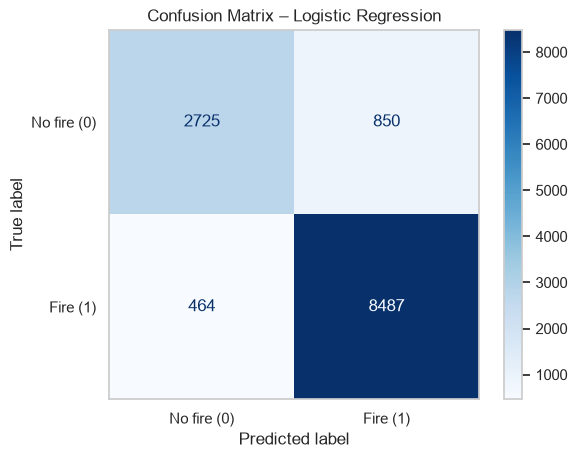

TN = 2725  |  FP (false alarms) = 850  |  FN (missed fires) = 464  |  TP = 8487


In [13]:
def plot_confusion(name, y_true, y_pred, cmap="Blues"):
    # Draw the confusion matrix with readable labels and return it
    cm = metrics.confusion_matrix(y_true, y_pred)
    disp = metrics.ConfusionMatrixDisplay(cm, display_labels=["No fire (0)", "Fire (1)"])
    disp.plot(cmap=cmap, values_format="d")
    plt.title(f"Confusion Matrix – {name}")
    plt.grid(False)
    plt.show()
    tn, fp, fn, tp = cm.ravel()
    print(f"TN = {tn}  |  FP (false alarms) = {fp}  |  FN (missed fires) = {fn}  |  TP = {tp}")
    return cm


cm_lr = plot_confusion("Logistic Regression", y_test, y_pred_lr, cmap="Blues")

#### Reading the results
The test set contains **8,951 real fires** and **3,575 normal samples**.
- **Missed fires (FN = 464, bottom-left cell):** the model detects 8,487 of the 8,951 fires, so **Recall = 8,487 / 8,951 = 0.9482**.
- **False alarms (FP = 850, top-right cell):** 850 of the 3,575 normal samples are classified as fire. Only 76.2% of the normal situations are recognised (Recall of class 0 = 0.7622).
- **Precision = 8,487 / (8,487 + 850) = 0.9090:** about 9 alarms out of 10 are real fires.

---
# 🏆 Bonus Challenge: XGBoost

### 1. Implement XGBoost
XGBoost builds an ensemble of decision trees one after the other; each new tree corrects the errors of the previous ones.
A tree splits on threshold values (for example `TVOC_ppb > 1000`), and these splits do not change when a feature is rescaled. XGBoost is therefore **not sensitive to feature scaling**, so it is trained on the **raw features**.

In [14]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,        # number of trees
    max_depth=6,             # maximum depth of each tree
    learning_rate=0.1,       # contribution of each new tree
    subsample=0.9,           # share of the rows used by each tree
    colsample_bytree=0.9,    # share of the features used by each tree
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

### 2. Train and evaluate (same train/test split, same metrics)

In [15]:
xgb.fit(X_train, y_train)          # same X_train / y_train as Logistic Regression, without scaling
y_pred_xgb = xgb.predict(X_test)

print("=== XGBoost ===")
res_xgb = evaluate("XGBoost", y_test, y_pred_xgb)
print("\nDetailed report per class:\n")
print(metrics.classification_report(y_test, y_pred_xgb, target_names=["0 = normal", "1 = fire"], digits=4))

=== XGBoost ===
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000

Detailed report per class:

              precision    recall  f1-score   support

  0 = normal     1.0000    1.0000    1.0000      3575
    1 = fire     1.0000    1.0000    1.0000      8951

    accuracy                         1.0000     12526
   macro avg     1.0000    1.0000    1.0000     12526
weighted avg     1.0000    1.0000    1.0000     12526



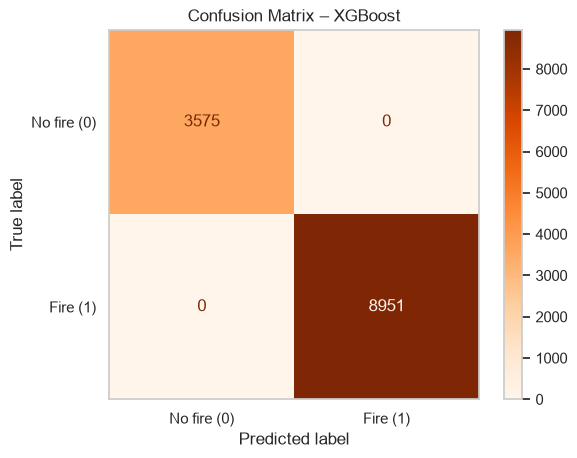

TN = 3575  |  FP (false alarms) = 0  |  FN (missed fires) = 0  |  TP = 8951


In [16]:
cm_xgb = plot_confusion("XGBoost", y_test, y_pred_xgb, cmap="Oranges")

### 3. Compare and analyze

,Accuracy,Precision,Recall,F1-Score,Missed fires (FN),False alarms (FP)
Model,,,,,,
Logistic Regression,0.8951,0.909,0.9482,0.9281,464,850
XGBoost,1.0000,1.000,1.0000,1.0000,0,0


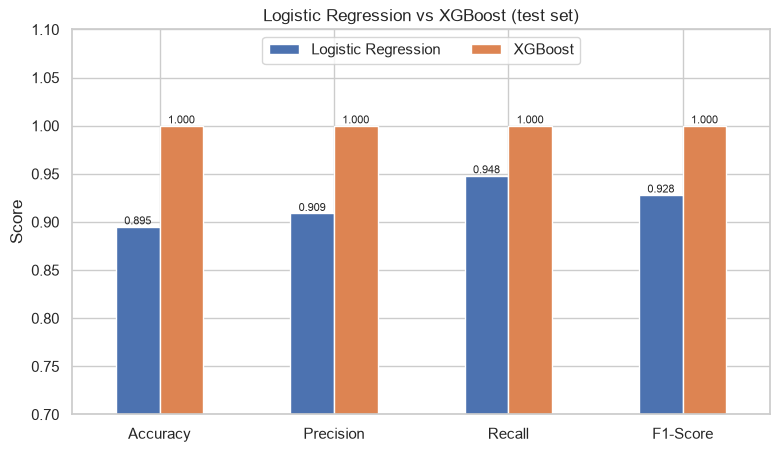

Model with the higher Recall: XGBoost


In [17]:
results = pd.DataFrame([res_lr, res_xgb]).set_index("Model")
results["Missed fires (FN)"] = [cm_lr[1, 0], cm_xgb[1, 0]]
results["False alarms (FP)"] = [cm_lr[0, 1], cm_xgb[0, 1]]
display(results.round(4))

ax = results[["Accuracy", "Precision", "Recall", "F1-Score"]].T.plot(
    kind="bar", figsize=(9, 5), rot=0, color=["#4C72B0", "#DD8452"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.title("Logistic Regression vs XGBoost (test set)")
plt.ylabel("Score")
plt.ylim(0.7, 1.1)
plt.legend(loc="upper center", ncol=2)
plt.show()

print("Model with the higher Recall:", results["Recall"].idxmax())

#### Simplicity and speed vs complexity
The cell below measures the training time, the prediction time on the whole test set, and the size of each trained model.
The times depend on the machine, so they change a little from one run to another.

In [18]:
import time

def mean_time_ms(fn, repeat):
    # Average run time of fn() in milliseconds
    start = time.perf_counter()
    for _ in range(repeat):
        fn()
    return (time.perf_counter() - start) / repeat * 1000

n_lr_params = log_reg.coef_.size + log_reg.intercept_.size          # one weight per feature + the bias
xgb_nodes = len(xgb.get_booster().trees_to_dataframe())             # all nodes of all trees

complexity = pd.DataFrame({
    "Train time (ms)": [
        mean_time_ms(lambda: LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_scaled, y_train), 3),
        mean_time_ms(lambda: XGBClassifier(**xgb.get_params()).fit(X_train, y_train), 1),
    ],
    "Predict test set (ms)": [
        mean_time_ms(lambda: log_reg.predict(X_test_scaled), 10),
        mean_time_ms(lambda: xgb.predict(X_test), 10),
    ],
    "Model size": [
        f"{n_lr_params} numbers ({log_reg.coef_.size} weights + 1 bias)",
        f"{xgb.n_estimators} trees, {xgb_nodes} nodes",
    ],
}, index=["Logistic Regression", "XGBoost"])
complexity.round(2)

,Train time (ms),Predict test set (ms),Model size
Logistic Regression,98.46,0.45,13 numbers (12 weights + 1 bias)
XGBoost,783.17,12.98,"300 trees, 4922 nodes"


#### Which model has the higher Recall?
**XGBoost**, with **Recall = 1.0000** (0 missed fires), against **0.9482** for Logistic Regression (464 missed fires). XGBoost is also better on every other metric: 0 false alarms against 850.

The relation between the sensors and the alarm is not linear. The gas and particle sensors stay close to 0 most of the time and jump to very large values during some events (see the `max before` column in A.5).
A tree can learn thresholds and combinations of sensors. Logistic Regression can only draw one straight boundary: a weighted sum of the scaled features compared to a threshold.

> **Read the 1.0000 with care.** The sensors record **one sample per second** (the `UTC` column increases by 1 s from one row to the next). A random split puts readings taken a few seconds apart in the training set and in the test set.
> The test set is therefore easier than readings from a new room or a new device, and the real-world scores of both models are expected to be lower.

#### Why is minimizing False Negatives crucial in fire detection?
- A **False Negative** is a real fire with **no alarm**. Nobody is warned, the evacuation and the call to the firefighters are delayed, and the fire keeps spreading. The result can be injuries, deaths and destroyed property: the cost is **very high and cannot be undone**.
- A **False Positive** is a **false alarm**. It is annoying and has a cost (an unnecessary evacuation or call-out), but it is **recoverable**.
- So, for a fire alarm, **Recall on the fire class is the most important metric**. Precision still matters: too many false alarms make people ignore or unplug the detector.

#### Trade-offs
| Criterion | Logistic Regression | XGBoost |
|---|---|---|
| Recall / F1-Score (test set) | 0.9482 / 0.9281 | **1.0000 / 1.0000** |
| Missed fires / false alarms | 464 / 850 | **0 / 0** |
| Feature scaling | Required (`StandardScaler`) | Not required |
| Training time (this run) | **98 ms** | 783 ms (about 8× slower) |
| Prediction time for the 12,526 test samples (this run) | **0.45 ms** | 13 ms (about 30× slower) |
| Model size | **13 numbers** (12 weights + 1 bias) | 300 trees, 4,922 nodes |
| Interpretability | **High**: the sign and size of each weight show the effect of each sensor | Lower: needs feature importance or SHAP |
| Non-linear relations | Not captured | Captured |

- **Logistic Regression → simplicity & speed.** It trains and predicts much faster, its whole model is 13 numbers, and one prediction is a weighted sum followed by a sigmoid. It is easy to explain and to run on a small IoT node. The price is lower performance: 464 missed fires and 850 false alarms on this test set.
- **XGBoost → higher performance, more complexity.** It gives the best detection here, but it needs 300 trees (4,922 nodes), more memory and more computation for each prediction, and its decisions are harder to explain.

---
# 📝 Conclusion

### Results on the test set
12,526 samples (20% of the data): 8,951 fires and 3,575 normal samples. Split with `random_state = 42`.

| Model | Accuracy | Precision | Recall | F1-Score | Missed fires (FN) | False alarms (FP) |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.8951 | 0.9090 | **0.9482** | 0.9281 | 464 | 850 |
| XGBoost (bonus) | 1.0000 | 1.0000 | **1.0000** | 1.0000 | 0 | 0 |

### Interpretation of the Recall of Logistic Regression
**Recall = TP / (TP + FN) = 8,487 / 8,951 = 0.9482.** The model detects 94.8% of the fire samples and misses 5.2% of them: **464 fires without an alarm**, about 1 in 19.
This Recall is higher than its Precision (0.9090) and much higher than the Recall of the normal class (0.7622). The model therefore leans towards answering *fire*, which is the safer direction for an alarm.
But 464 missed fires is still too many for a safety device.

### Implications for IoT fire alarm reliability
- **Missed fires are the critical risk.** With Logistic Regression at the default threshold of 0.5, about 5 fire readings out of 100 do not trigger the alarm. Used alone, this model is not reliable enough to protect people.
- **False alarms also reduce reliability.** 850 of the 3,575 normal readings (23.8%) trigger the alarm. Frequent false alarms lead users to ignore or disconnect the detector, and then a real fire is missed as well.
- **Ways to improve Logistic Regression:** lower the decision threshold below 0.5 to detect more fires (at the cost of more false alarms), or transform the very skewed gas and particle sensors before scaling.
- **XGBoost** removes both errors on this test set. Because the test readings are taken a few seconds away from training readings, this score is optimistic. Before deployment, a detector must be tested on **new recordings**: other rooms, devices and fire types.
- **Edge deployment:** Logistic Regression needs 13 numbers and almost no computation, so it can run on any microcontroller. XGBoost is more accurate but heavier (300 trees, 4,922 nodes). An IoT system can run the light model on the device and the stronger model on a gateway or in the cloud, or use XGBoost on the device if it has enough memory.